In [3]:
import math
import numpy as np
import matplotlib.pyplot as g
import torch
from  graphviz import Digraph
%matplotlib inline

In [ ]:
## Linear Equation and its slope

y = mx + c (line equation)
where m is slope

or
y = ax + b
where a is slope

or

Wx + b = y 

where W is weight matrix

### Derivative as Rate of change
How does y (output) changes when x changes ? > it's W

In [7]:
def f(x):
    # maybe, a loss code
    return (x ** 2) + 4 * x - 5

In [8]:
Xs = np.arange(-10, 10, 0.5)

In [9]:
Ys = f(Xs)

In [10]:
print(Ys)

[ 55.    47.25  40.    33.25  27.    21.25  16.    11.25   7.     3.25
   0.    -2.75  -5.    -6.75  -8.    -8.75  -9.    -8.75  -8.    -6.75
  -5.    -2.75   0.     3.25   7.    11.25  16.    21.25  27.    33.25
  40.    47.25  55.    63.25  72.    81.25  91.   101.25 112.   123.25]


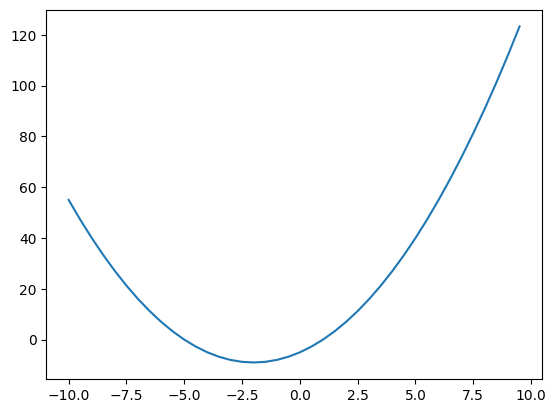

In [11]:
g.plot(Xs, Ys)

In [12]:
a = 6 
b = -4
c = 10
d = a * b + c

In [14]:
class Scalar:
    
    def __init__(self, value, label, oprt = '', children = ()):
        # self = Jyane he function call kele ahe to/ti
        self.value = value
        self.label = label
        self.oprt  = oprt
        self.children = children
        self.der = 0.0

    def __add__(self, other):
        return Scalar(self.value + other.value, '', oprt='+', children=(self, other))

    def __mul__(self, other):
        return Scalar(self.value * other.value, '', oprt='*', children=(self, other))

    def relu(self):
        return Scalar(0 if self.value < 0 else self.value, '', oprt = 'ReLU', children=(self,))

In [17]:
a = Scalar(6, 'a')
b = Scalar(-4, 'b')
c = Scalar(10, 'c')
d = a * b +c

In [18]:
d.label = 'd'

In [21]:
def trace(root):

    nodes = set() 
    edges = set()
    
    def build(v):
        if v not in nodes:
            nodes.add(v)

            for child in v.children:
                edges.add((child,v))
                build(child)

    build(root)
    return nodes, edges
        

In [22]:
trace(d)

({<__main__.Scalar at 0x10e1b82b0>,
  <__main__.Scalar at 0x10e1b8a00>},
 {(<__main__.Scalar at 0x10e1b82b0>, <__main__.Scalar at 0x10e1b8850>),
  (<__main__.Scalar at 0x10e1b8820>, <__main__.Scalar at 0x10e1b82b0>),
  (<__main__.Scalar at 0x10e1b88b0>, <__main__.Scalar at 0x10e1b82b0>),
  (<__main__.Scalar at 0x10e1b8a00>, <__main__.Scalar at 0x10e1b8850>)})

In [23]:

class MermaidGraph:
    """Wraps Mermaid source so Jupyter renders it inline, like a graphviz Digraph."""
    def __init__(self, source):
        self.source = source

    def _repr_mimebundle_(self, include=None, exclude=None):
        return {
            'text/vnd.mermaid': self.source,                      # JupyterLab 4.1+ / Notebook 7.1+
            'text/markdown': f"```mermaid\n{self.source}\n```",   # fallback renderer
            'text/plain': self.source,
        }

    def __str__(self):
        return self.source


def draw_mermaid(root, rankdir='LR'):
    nodes, edges = trace(root)

    def esc(s):
        return str(s).replace('"', '#quot;')   # Mermaid's escape for quotes

    lines = [f"flowchart {rankdir}"]

    for n in nodes:
        nid = f"n{id(n)}"
        lines.append(f'    {nid}["{esc(n.label)} | Val {n.value:.4f} | Der {n.der:.4f}"]')
        if n.oprt:
            lines.append(f'    {nid}_op(("{esc(n.oprt)}"))')
            lines.append(f'    {nid}_op --> {nid}')

    for n1, n2 in edges:
        lines.append(f'    n{id(n1)} --> n{id(n2)}_op')

    return MermaidGraph("\n".join(lines))


def draw_graph(root, format='svg', rankdir='TB'):
    nodes, edges = trace(root)
    
    graph = Digraph(
        format=format,
        graph_attr={'rankdir': rankdir, 'bgcolor': 'transparent'},
        node_attr={
            'style': 'filled',
            'fillcolor': '#2d2d2d',
            'color': '#d4d4d4',
            'fontcolor': '#d4d4d4',
            'fontname': 'Helvetica',
        },
        edge_attr={'color': '#d4d4d4'},
    )
    
    for n in nodes:
        graph.node(name=str(id(n)), label = "{ %s | Val %.4f | Der %.4f }" % (n.label, n.value, n.der), shape='record')
        if n.oprt:
            graph.node(name=str(id(n)) + n.oprt, label=n.oprt, fillcolor='#264f78', color='#569cd6', fontcolor='#ffffff')
            graph.edge(str(id(n)) + n.oprt, str(id(n)))
    
    for n1, n2 in edges:
        graph.edge(str(id(n1)), str(id(n2)) + n2.oprt)
    
    return graph

In [24]:
draw_mermaid(d)

```mermaid
flowchart LR
    n4531653120["c | Val 10.0000 | Der 0.0000"]
    n4531652640["b | Val -4.0000 | Der 0.0000"]
    n4531652688["d | Val -14.0000 | Der 0.0000"]
    n4531652688_op(("+"))
    n4531652688_op --> n4531652688
    n4531651248[" | Val -24.0000 | Der 0.0000"]
    n4531651248_op(("*"))
    n4531651248_op --> n4531651248
    n4531652784["a | Val 6.0000 | Der 0.0000"]
    n4531652640 --> n4531651248_op
    n4531651248 --> n4531652688_op
    n4531653120 --> n4531652688_op
    n4531652784 --> n4531651248_op
```

## Partial Derivatives

In [30]:
a = Scalar(3, label='a')
b = Scalar(-2, label='b')
c = Scalar(10, label='c')
e = a * b # e is made of a and b => a and b are CHILDREN of e
e.label = 'e'
d = c + e # d is made of c and e => c and e are CHILDREN of d
d.label = 'd'
f = Scalar(-3, label='f') 
L = d * f # L is made of d & f
L.label = 'L'

In [31]:
draw_graph(L, rankdir='BT')

ExecutableNotFound: failed to execute PosixPath('dot'), make sure the Graphviz executables are on your systems' PATH

In [31]:
draw_graph(L, rankdir='BT')

ExecutableNotFound: failed to execute PosixPath('dot'), make sure the Graphviz executables are on your systems' PATH

## Partial derivative definition and hand calculation
a
b
c
are scalars
e = a * b
d = c + e
f = Scalar(-3, label='f')
L = d * f

How the final output changes 
How the L changes wrt (all inputs one by one, including itselt)

### der(L) wrt L

```
dL
__ = 1
dL
```

### der(L) wrt d

L = d * f

L = 5 * d

```
dL
__ = f  (because we always multiply d by f)
dd
```


### der(L) wrt f

```
dL
__ =  d
df 
```

### der(L) wrt c
```
dL    dL       dd
__ =  ___  X   __  = f X 1 = f
dc    dd       dc

```
d = c + e
  = 1 + 0 

```
dd
___ =  1
dc 
```


### der(L) wrt e

```
dL    dL       dd
__ =  ___  X   __  = f X 1 = f
de    dd       de
```

d = c + e
  = 0 + 1 

```
dd
___ =  1
de 
```

### der(L) wrt a

e = a * b

```
de
__ = b
da

dL    dL     de 
__ = ____ X ____  = f X b = fb
da    de     da



dL    dL     dd     de 
__ = ____ X ____ X ____
da    dd     de     da

   = How L is changed by d (multiply)
     How d is changed by e (multiply)
     How e is changed by a
```


### der(L) wrt b

e = a * b
```
de
__ = a
db


dL    dL     dd     de 
__ = ____ X ____ X ____ = f  X 1 X a = fa
db    dd     de     db
```